# Role 3 – Graph Neural Networks for Anti-Money Laundering on Elliptic
**BSFS × BSML – Graph ML for Money Laundering**

**Research question:** does learning on the Bitcoin transaction graph (GNNs) beat models that look at each transaction in isolation?

| | |
|---|---|
| **Dataset** | Elliptic Bitcoin dataset – 203,769 transactions (nodes), 234,355 payment flows (edges), 49 time steps, 165 features per node |
| **Task** | Binary node classification: *illicit* (1) vs *licit* (0); unlabeled nodes are used for message passing only |
| **Split** | Temporal, same as Weber et al. (2019): train on time steps 1–34, test on 35–49 |
| **Models** | MLP (no graph, control) · GCN · GraphSAGE · GAT · Random Forest (raw features, and raw + GCN embeddings) |
| **Main metrics** | Illicit-class F1, precision, recall, PR-AUC; 5 random seeds, reported as mean ± std |
| **Reference** | Weber et al. (2019), *Anti-Money Laundering in Bitcoin: Experimenting with Graph Convolutional Networks for Financial Forensics*, KDD Workshop – [arXiv:1908.02591](https://arxiv.org/abs/1908.02591) |

### Contents
1. Setup and data loading
2. Graph construction and strict temporal split
3. Model definitions
4. Training loop, class imbalance and evaluation
5. Results: GNNs vs MLP (5 seeds)
6. Results per time step (dark-market shutdown)
7. Extra: GNN embeddings + Random Forest
8. Comparison with Weber et al. (2019)
9. Conclusions, limitations and next steps
10. Export results for Role 4

> **To run:** Runtime → Change runtime type → **T4 GPU**, then Runtime → Run all (≈10–15 min). The outputs saved in this notebook come from one full run; sections 8 and 10 must be re-run to show their output.

## 1. Setup and data loading
`torch_geometric` (PyG) is the graph deep-learning library on top of PyTorch; `kagglehub` downloads the dataset from Kaggle.

In [ ]:
# Install PyTorch Geometric and the Kaggle downloader (PyTorch is already installed on Colab)
!pip install -q torch_geometric kagglehub

The dataset comes as three CSV files:
- `elliptic_txs_features.csv` – one row per transaction: `txId`, `time_step`, then 165 anonymised features (the first 93 describe the transaction itself, the other 72 aggregate information from its one-hop neighbours);
- `elliptic_txs_classes.csv` – label per transaction: `1` = illicit, `2` = licit, `unknown`;
- `elliptic_txs_edgelist.csv` – directed edges `txId1 → txId2` (Bitcoin flowing from one transaction to the next).

If the automatic download asks for credentials, upload the three CSVs manually and set `DATA_DIR` to their folder.
**If Role 1 provides a shared loader/split, use it so that all roles report comparable numbers.**

In [ ]:
import os, glob, random
import numpy as np, pandas as pd, torch
import torch.nn.functional as F

# ---- Download (or point to) the data -------------------------------------
DATA_DIR = None  # e.g. "/content/elliptic_bitcoin_dataset" if you uploaded the files yourself
if DATA_DIR is None:
    import kagglehub
    DATA_DIR = kagglehub.dataset_download("ellipticco/elliptic-data-set")

def find(name):
    """Return the path of a file anywhere inside DATA_DIR."""
    return glob.glob(os.path.join(DATA_DIR, "**", name), recursive=True)[0]

feat = pd.read_csv(find("elliptic_txs_features.csv"), header=None)   # no header in this file
cls = pd.read_csv(find("elliptic_txs_classes.csv"))
edges = pd.read_csv(find("elliptic_txs_edgelist.csv"))

# ---- Name the columns and attach the labels --------------------------------
feat.columns = ["txId", "time_step"] + [f"f{i}" for i in range(feat.shape[1] - 2)]
df = feat.merge(cls, on="txId", how="left")      # left join keeps the original node order
# class "1" = illicit, "2" = licit, "unknown" = no label
df["y"] = df["class"].astype(str).map({"1": 1, "2": 0, "unknown": -1})

# ---- Feature sets -------------------------------------------------------------
LOCAL_FEATS = [f"f{i}" for i in range(93)]          # transaction's own features
ALL_FEATS = [c for c in df.columns if c.startswith("f")]  # + 72 aggregated neighbour features
FEATURES = ALL_FEATS   # try LOCAL_FEATS too: GNNs should help more when aggregated features are removed

print(df.shape, edges.shape)
print(df["y"].value_counts())

Using Colab cache for faster access to the 'elliptic-data-set' dataset.
(203769, 169) (234355, 2)
y
-1    157205
 0     42019
 1      4545
Name: count, dtype: int64


**What we see:** 77% of the nodes are unlabeled (`-1`). Among the 46,564 labeled nodes only **9.8% are illicit** (4,545 vs 42,019), so the classes are strongly imbalanced. Accuracy would therefore be misleading (always predicting "licit" gives ≈90%), which is why we focus on illicit-class F1 and PR-AUC.

## 2. Graph construction and strict temporal split

**From tables to a graph.** PyG represents a graph as a `Data` object with
- `x` – node feature matrix `[num_nodes, num_features]`;
- `edge_index` – a `[2, num_edges]` tensor of (source, target) node indices;
- `y` – node labels.

Transaction IDs are mapped to row indices 0…N-1. Edges are made **undirected**, so information flows both from payers and from payees.

**Strict temporal split.** We follow the paper: time steps 1–34 for training and 35–49 for testing. Inside the training period, time steps 30–34 are held out as **validation** (for early stopping and choosing the decision threshold):

| Set | Time steps | Used for |
|---|---|---|
| train | 1–29 | gradient updates |
| validation | 30–34 | early stopping, threshold selection |
| test | 35–49 | final evaluation only |

Each set is built as a **separate subgraph**. During training the model never sees test-period nodes, their features or their labels. This is the *inductive* setting used by Weber et al. In Elliptic, edges only connect transactions within the same time step, so cutting the graph by time step removes no edges.

Features are standardised with the **training-set** mean and standard deviation only, so no test information leaks in.

In [ ]:
from torch_geometric.data import Data
from torch_geometric.utils import to_undirected, subgraph

# ---- Edge list: transaction IDs -> node indices ---------------------------
N = len(df)
id2idx = pd.Series(np.arange(N), index=df["txId"].values)
src = id2idx.loc[edges["txId1"].values].values
dst = id2idx.loc[edges["txId2"].values].values
edge_index = to_undirected(torch.tensor(np.vstack([src, dst]), dtype=torch.long), num_nodes=N)

# ---- Node tensors -------------------------------------------------------------
x_all = torch.tensor(df[FEATURES].values, dtype=torch.float)
y_all = torch.tensor(df["y"].values, dtype=torch.long)
t_all = torch.tensor(df["time_step"].values, dtype=torch.long)

# Team split: train = time steps 1-34, test = 35-49.
# Inside the training period we hold out 30-34 as validation (early stopping + threshold choice).
TRAIN_END, VAL_START, TEST_START = 29, 30, 35

def make_graph(node_mask):
    # Keep only nodes (and edges between them) from these time steps:
    # the model never sees test-period nodes, features or labels during training.
    ei, _ = subgraph(node_mask, edge_index, relabel_nodes=True, num_nodes=N)
    return Data(x=x_all[node_mask], edge_index=ei, y=y_all[node_mask], t=t_all[node_mask])

train_g = make_graph(t_all <= TRAIN_END)
val_g   = make_graph((t_all >= VAL_START) & (t_all < TEST_START))
test_g  = make_graph(t_all >= TEST_START)

# Standardise with TRAIN statistics only
mu, sd = train_g.x.mean(0), train_g.x.std(0) + 1e-6
for g in (train_g, val_g, test_g):
    g.x = (g.x - mu) / sd
    g.labeled = g.y >= 0          # loss and metrics use labeled nodes only

for name, g in [("train", train_g), ("val", val_g), ("test", test_g)]:
    lab = g.y[g.labeled]
    print(f"{name}: {g.num_nodes} nodes, {g.edge_index.size(1)} edges, "
          f"{int(g.labeled.sum())} labeled, illicit share {lab.float().mean():.3f}")

# Move everything to the GPU if available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
train_g, val_g, test_g = train_g.to(device), val_g.to(device), test_g.to(device)
print("device:", device)

/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


train: 120804 nodes, 280446 edges, 26381 labeled, illicit share 0.109
val: 15461 nodes, 33240 edges, 3513 labeled, illicit share 0.168
test: 67504 nodes, 155024 edges, 16670 labeled, illicit share 0.065
device: cuda


**What we see:** the share of illicit transactions moves over time: **10.9%** in train, **16.8%** in validation and only **6.5%** in test. The three sets therefore differ in distribution (*distribution shift*), which matters later: a decision threshold tuned on validation may not be optimal on test. (The `torch.jit.script` FutureWarning comes from the library and can be ignored.)

## 3. Model definitions

All models share the same skeleton: **2 hidden layers of width 64 → ReLU → dropout 0.3 → linear output layer (2 classes)**. Only the type of layer changes, so differences in results come from *how* each model uses the graph:

| Model | One layer computes, for node *v* | Uses the graph? |
|---|---|---|
| **MLP** | `W · h_v` | No – control model |
| **GCN** (Kipf & Welling 2017) | degree-normalised **average** of `W · h_u` over *v* and its neighbours | Yes |
| **GraphSAGE** (Hamilton et al. 2017) | `W₁ · h_v + W₂ · mean(h_u for neighbours u)` – keeps the node's own signal separate | Yes |
| **GAT** (Veličković et al. 2018) | weighted sum of neighbours, with weights learned by **attention** (4 heads × 16 dims) | Yes |

With 2 layers each node aggregates information from its **2-hop neighbourhood**. The `mlp` model has exactly the same depth and width but ignores edges, so **GNN vs MLP measures the value of the graph itself**.

`embed()` returns the last hidden representation (64-dim node embedding), which is reused in Section 7.

In [ ]:
from torch_geometric.nn import GCNConv, SAGEConv, GATConv

class Net(torch.nn.Module):
    """Generic 2-layer network: kind in {"mlp", "gcn", "sage", "gat"}."""
    def __init__(self, kind, in_dim, hid=64, n_layers=2, dropout=0.3, heads=4):
        super().__init__()
        self.kind, self.dropout = kind, dropout
        self.convs = torch.nn.ModuleList()
        dims = [in_dim] + [hid] * n_layers               # e.g. [165, 64, 64]
        for i, o in zip(dims[:-1], dims[1:]):
            if kind == "gcn":   self.convs.append(GCNConv(i, o))
            elif kind == "sage": self.convs.append(SAGEConv(i, o))
            elif kind == "gat":  self.convs.append(GATConv(i, o // heads, heads=heads))  # heads are concatenated -> o dims
            elif kind == "mlp":  self.convs.append(torch.nn.Linear(i, o))                # same size, no edges
            else: raise ValueError(kind)
        self.head = torch.nn.Linear(hid, 2)              # classifier: licit / illicit

    def embed(self, x, edge_index):
        """Node embeddings after the hidden layers (used in Section 7)."""
        for conv in self.convs:
            x = conv(x) if self.kind == "mlp" else conv(x, edge_index)
            x = F.relu(x)
            x = F.dropout(x, self.dropout, self.training)
        return x

    def forward(self, x, edge_index):
        return self.head(self.embed(x, edge_index))      # logits [num_nodes, 2]

## 4. Training loop, class imbalance and evaluation

- **Full-batch training:** the whole training graph (≈121k nodes) fits on the GPU, so each epoch is one forward/backward pass. The loss is computed on **labeled nodes only**; unlabeled nodes still pass messages to their neighbours.
- **Class imbalance:** weighted cross-entropy with weights inversely proportional to class frequency (`n / (2 · n_class)`). This gives ≈0.56 for licit and ≈4.59 for illicit, so a missed illicit transaction costs about 8× more than a false alarm. (Weber et al. used a milder 0.3/0.7 weighting.)
- **Early stopping:** Adam (lr = 0.005, weight decay = 5e-4), up to 500 epochs. After every epoch we compute validation **PR-AUC** and keep the best weights; training stops after 50 epochs without improvement.
- **Decision threshold:** instead of a fixed 0.5, we choose the probability threshold that maximises illicit F1 on **validation** and apply it unchanged to the test set.
- **Metrics (illicit class, test set):** F1, precision (how many alerts are truly illicit), recall (how many illicit transactions are caught) and PR-AUC. PR-AUC does not depend on the threshold, so it is a cleaner way to compare models.
- **Reproducibility:** `set_seed` fixes Python, NumPy and PyTorch seeds. Some GPU scatter operations are not fully deterministic, so tiny run-to-run differences are possible. That is one reason we report mean ± std over seeds.

In [ ]:
from sklearn.metrics import f1_score, precision_score, recall_score, average_precision_score

def set_seed(s):
    """Fix all random number generators for reproducibility."""
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

# ---- Class weights from the TRAINING labels -----------------------------------
counts = torch.bincount(train_g.y[train_g.labeled], minlength=2).float()
class_w = (counts.sum() / (2 * counts)).to(device)
print("class weights:", class_w.tolist())

@torch.no_grad()
def predict(model, g):
    """Illicit probability, true label and time step for the labeled nodes of graph g."""
    model.eval()
    p = torch.softmax(model(g.x, g.edge_index), 1)[:, 1]
    m = g.labeled
    return p[m].cpu().numpy(), g.y[m].cpu().numpy(), g.t[m].cpu().numpy()

def best_threshold(p, y):
    """Threshold in [0.05, 0.95] that maximises illicit F1 (chosen on validation)."""
    ths = np.linspace(0.05, 0.95, 91)
    return ths[int(np.argmax([f1_score(y, p >= th, zero_division=0) for th in ths]))]

def run(kind, seed, epochs=500, patience=50, lr=5e-3, wd=5e-4, **kw):
    """Train one model with one seed; return (model, test metrics, per-time-step F1)."""
    set_seed(seed)
    model = Net(kind, train_g.num_features, **kw).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=wd)
    best, best_state, bad = -1, None, 0
    for ep in range(epochs):
        # -- one full-batch training step on the training subgraph --
        model.train(); opt.zero_grad()
        out = model(train_g.x, train_g.edge_index)
        loss = F.cross_entropy(out[train_g.labeled], train_g.y[train_g.labeled], weight=class_w)
        loss.backward(); opt.step()
        # -- early stopping on validation PR-AUC --
        pv, yv, _ = predict(model, val_g)
        ap = average_precision_score(yv, pv)
        if ap > best:
            best, bad = ap, 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= patience: break
    # -- restore best weights, pick threshold on validation, evaluate on test --
    model.load_state_dict(best_state)
    pv, yv, _ = predict(model, val_g)
    th = best_threshold(pv, yv)
    pt, yt, tt = predict(model, test_g)
    pred = pt >= th
    res = dict(model=kind, seed=seed, epochs=ep + 1, threshold=th,
               illicit_f1=f1_score(yt, pred), precision=precision_score(yt, pred, zero_division=0),
               recall=recall_score(yt, pred), pr_auc=average_precision_score(yt, pt))
    per_t = {int(s): f1_score(yt[tt == s], pred[tt == s], zero_division=0) for s in np.unique(tt)}
    return model, res, per_t

class weights: [0.5610591173171997, 4.5943922996521]


## 5. Results: GNNs vs MLP (5 seeds)
Every architecture is trained with seeds 0–4. The table reports mean and standard deviation of the test metrics.

In [ ]:
SEEDS = [0, 1, 2, 3, 4]
MODELS = ["mlp", "gcn", "sage", "gat"]
results, per_step, trained = [], [], {}
for kind in MODELS:
    for s in SEEDS:
        model, res, per_t = run(kind, s)
        results.append(res)
        per_step += [dict(model=kind, seed=s, time_step=k, f1=v) for k, v in per_t.items()]
        trained[(kind, s)] = model            # kept for the embedding experiment (Section 7)
        print(f"{kind:5s} seed {s}: F1={res['illicit_f1']:.3f}  PR-AUC={res['pr_auc']:.3f}  ({res['epochs']} epochs)")

# ---- Mean +- std over seeds ----------------------------------------------------
res_df = pd.DataFrame(results)
summary = res_df.groupby("model")[["illicit_f1", "precision", "recall", "pr_auc"]].agg(["mean", "std"]).round(3)
summary

mlp   seed 0: F1=0.477  PR-AUC=0.346  (124 epochs)
mlp   seed 1: F1=0.492  PR-AUC=0.327  (237 epochs)
mlp   seed 2: F1=0.544  PR-AUC=0.418  (444 epochs)
mlp   seed 3: F1=0.504  PR-AUC=0.320  (201 epochs)
mlp   seed 4: F1=0.518  PR-AUC=0.349  (220 epochs)
gcn   seed 0: F1=0.552  PR-AUC=0.519  (266 epochs)
gcn   seed 1: F1=0.492  PR-AUC=0.506  (217 epochs)
gcn   seed 2: F1=0.584  PR-AUC=0.517  (225 epochs)
gcn   seed 3: F1=0.590  PR-AUC=0.615  (276 epochs)
gcn   seed 4: F1=0.570  PR-AUC=0.550  (355 epochs)
sage  seed 0: F1=0.582  PR-AUC=0.496  (246 epochs)
sage  seed 1: F1=0.574  PR-AUC=0.517  (179 epochs)
sage  seed 2: F1=0.536  PR-AUC=0.472  (187 epochs)
sage  seed 3: F1=0.534  PR-AUC=0.480  (195 epochs)
sage  seed 4: F1=0.551  PR-AUC=0.489  (145 epochs)
gat   seed 0: F1=0.471  PR-AUC=0.296  (160 epochs)
gat   seed 1: F1=0.530  PR-AUC=0.524  (246 epochs)
gat   seed 2: F1=0.474  PR-AUC=0.365  (164 epochs)
gat   seed 3: F1=0.450  PR-AUC=0.406  (187 epochs)
gat   seed 4: F1=0.494  PR-AUC=

illicit_f1        precision        recall        pr_auc       
            mean    std      mean    std   mean    std   mean    std
model                                                               
gat        0.484  0.030     0.487  0.057  0.484  0.024  0.417  0.093
gcn        0.558  0.040     0.681  0.029  0.474  0.051  0.541  0.044
mlp        0.507  0.026     0.493  0.054  0.525  0.007  0.352  0.039
sage       0.555  0.022     0.557  0.054  0.557  0.015  0.491  0.017

### Interpretation

| Model | Illicit F1 | Precision | Recall | PR-AUC |
|---|---|---|---|---|
| MLP (no graph) | 0.507 ± 0.026 | 0.493 | 0.525 | 0.352 ± 0.039 |
| **GCN** | **0.558 ± 0.040** | **0.681** | 0.474 | **0.541 ± 0.044** |
| **GraphSAGE** | 0.555 ± 0.022 | 0.557 | **0.557** | 0.491 ± 0.017 |
| GAT | 0.484 ± 0.030 | 0.487 | 0.484 | 0.417 ± 0.093 |

1. **The graph helps the neural networks.** GCN and GraphSAGE gain about **+5 F1 points** over the identical MLP. On PR-AUC the gain is even larger: **0.35 → 0.54** for GCN, a 54% relative improvement. The 5-seed standard deviations (2–4 points) are smaller than these gaps, so the improvement is not just seed noise.
2. **GCN and GraphSAGE are about tied on F1, but trade off differently.** GCN is more *precise* (68% of its alerts are truly illicit). GraphSAGE has higher *recall* and is the most stable model (lowest std). In an AML setting this choice is a business decision: fewer false alarms for investigators (GCN) or fewer missed cases (SAGE).
3. **GAT is the weakest and least stable model** (PR-AUC std 0.093, ranging from 0.30 to 0.52 across seeds). Attention adds parameters to learn from relatively few illicit labels, and it would need dedicated tuning (lower learning rate, more dropout).
4. Early stopping kicked in after roughly 125–445 epochs, so the 500-epoch budget was sufficient.

## 6. Results per time step (dark-market shutdown)
Weber et al. report that at **time step 43** a large dark market was suddenly shut down. After that point, every model they tested fails to detect new illicit activity. We check whether the same happens here.

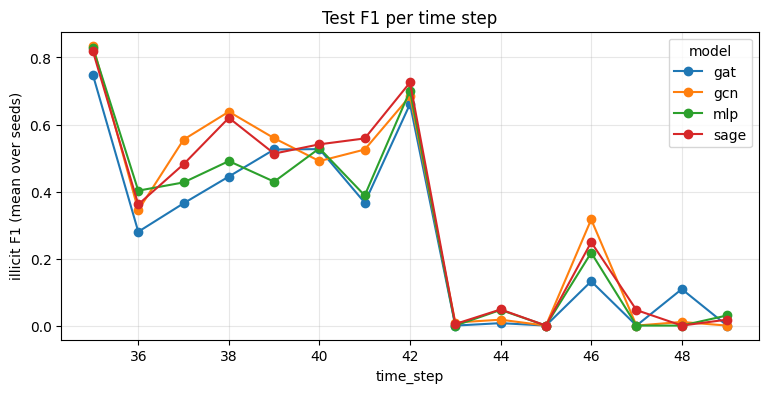

In [ ]:
import matplotlib.pyplot as plt

# Mean illicit F1 over the 5 seeds, for each model and each test time step
ps = pd.DataFrame(per_step).groupby(["model", "time_step"])["f1"].mean().unstack(0)
ax = ps.plot(marker="o", figsize=(9, 4))
ax.set_ylabel("illicit F1 (mean over seeds)"); ax.set_title("Test F1 per time step")
plt.grid(alpha=.3); plt.show()

### Interpretation
- **Time steps 35–42:** the models work reasonably (F1 between ≈0.3 and 0.8). Here GCN and GraphSAGE are usually above the MLP (for example at steps 37–38 and 41), and GAT is usually the lowest.
- **From time step 43 onwards, all models collapse to F1 ≈ 0**, with a single partial recovery at step 46. This **reproduces the key finding of Weber et al.**: after the dark-market shutdown, illicit behaviour changes, and patterns learned on the past no longer apply. The authors note that even a Random Forest retrained at every step could not cope with this.
- **Consequence:** the overall test F1 averages a "working" period with a "broken" one. When comparing models, it is worth also reporting F1 on steps 35–42 only. From an AML perspective, this shows why deployed models need monitoring for concept drift and regular retraining.

## 7. Extra: GNN embeddings + Random Forest
Weber et al. found that a **Random Forest (RF)** on the raw features is the strongest model, and that adding GCN node embeddings to its features (`AF+NE`) helps slightly. We reproduce both settings:
- `rf_raw`: RF on the 165 standardised features;
- `rf_raw+gcn_emb`: RF on the 165 features + the 64-dim embedding produced by the trained GCN (one GCN per seed).

The RF uses the paper's hyperparameter `max_features = 50` (with 100 trees instead of 50). It is trained on the **full** training period (time steps 1–34) and uses a fixed 0.5 threshold.

In [ ]:
from sklearn.ensemble import RandomForestClassifier

@torch.no_grad()
def emb(model, g):
    """64-dim embeddings of the labeled nodes of g, from a trained GNN."""
    model.eval()
    return model.embed(g.x, g.edge_index)[g.labeled].cpu().numpy()

def xy(g):
    """Raw (standardised) features and labels of the labeled nodes of g."""
    return g.x[g.labeled].cpu().numpy(), g.y[g.labeled].cpu().numpy()

# RF is trained on the full training period (1-34) = train + val
Xtr = np.vstack([xy(train_g)[0], xy(val_g)[0]]); ytr = np.concatenate([xy(train_g)[1], xy(val_g)[1]])
Xte, yte = xy(test_g)

rf_rows = []
for s in SEEDS:
    gnn = trained[("gcn", s)]   # try "sage" / "gat" too
    Etr = np.vstack([emb(gnn, train_g), emb(gnn, val_g)]); Ete = emb(gnn, test_g)
    for name, A, B in [("rf_raw", Xtr, Xte), ("rf_raw+gcn_emb", np.hstack([Xtr, Etr]), np.hstack([Xte, Ete]))]:
        rf = RandomForestClassifier(n_estimators=100, max_features=50, n_jobs=-1, random_state=s).fit(A, ytr)
        p = rf.predict_proba(B)[:, 1]
        rf_rows.append(dict(model=name, seed=s, illicit_f1=f1_score(yte, p >= 0.5),
                            pr_auc=average_precision_score(yte, p)))
pd.DataFrame(rf_rows).groupby("model")[["illicit_f1", "pr_auc"]].agg(["mean", "std"]).round(3)

illicit_f1        pr_auc       
                     mean    std   mean    std
model                                         
rf_raw              0.814  0.002  0.783  0.002
rf_raw+gcn_emb      0.758  0.015  0.740  0.013

### Interpretation
1. **The Random Forest is by far the best model:** illicit F1 **0.814 ± 0.002** and PR-AUC **0.783**, against 0.558 / 0.541 for the best GNN. This matches the paper's main conclusion (*"superiority of Random Forest"*). It is also a useful sanity check: our RF slightly exceeds the paper's 0.788, which suggests that our data pipeline and split are correct.
2. **Adding the GCN embeddings made the RF worse** (0.814 → 0.758), unlike in the paper (0.788 → 0.796). The most likely explanation is **overfitting of the embeddings**. The GCN was trained on the labels of time steps 1–29, so on those nodes its embeddings are "too good". The RF learns to rely on them, but on unseen test nodes they are much less reliable. A fair version would compute **out-of-fold embeddings**: train the GCN on one part of the training period and embed the other part. An alternative is unsupervised embeddings such as Node2Vec (Role 2).
3. Why might trees beat GNNs here? The 72 aggregated features already encode much of the neighbourhood information that a GNN would learn. Tree ensembles also handle skewed, heterogeneous tabular features and class imbalance very well, without any scaling or tuning.

## 8. Comparison with Weber et al. (2019)

Reference values are taken from Table 1 (and Table 2 for EvolveGCN) of the paper. They use the same temporal split (train 1–34 / test 35–49) and the illicit class as positive. *AF* = all features, *NE* = GCN node embeddings appended. Our values are mean ± std over 5 seeds.

| Model | Paper P | Paper R | Paper F1 | Ours P | Ours R | Ours F1 |
|---|---|---|---|---|---|---|
| Random Forest (AF) | 0.956 | 0.670 | 0.788 | – | – | **0.814 ± 0.002** |
| Random Forest (AF + NE) | 0.971 | 0.675 | **0.796** | – | – | 0.758 ± 0.015 |
| MLP (AF) | 0.694 | 0.617 | 0.653 | 0.493 | 0.525 | 0.507 ± 0.026 |
| GCN | 0.812 | 0.512 | 0.628 | 0.681 | 0.474 | 0.558 ± 0.040 |
| GraphSAGE | – | – | – | 0.557 | 0.557 | 0.555 ± 0.022 |
| GAT | – | – | – | 0.487 | 0.484 | 0.484 ± 0.030 |
| Skip-GCN | 0.812 | 0.623 | 0.705 | – | – | – |
| EvolveGCN | 0.850 | 0.624 | 0.720 | – | – | – |

The next cell rebuilds this table and a chart directly from the results in memory. **Run it after Sections 5 and 7.**

In [ ]:
# ---- Reference results: Weber et al. (2019), Table 1 / Table 2 (illicit class, test set) ----
paper = pd.DataFrame([
    ("Random Forest (AF)",      0.956, 0.670, 0.788),
    ("Random Forest (AF + NE)", 0.971, 0.675, 0.796),
    ("MLP (AF)",                0.694, 0.617, 0.653),
    ("GCN",                     0.812, 0.512, 0.628),
    ("Skip-GCN",                0.812, 0.623, 0.705),
    ("EvolveGCN",               0.850, 0.624, 0.720),
], columns=["model", "paper_precision", "paper_recall", "paper_f1"])

# ---- Our results (mean and std over seeds) ---------------------------------------
name_map = {"mlp": "MLP (AF)", "gcn": "GCN", "sage": "GraphSAGE", "gat": "GAT",
            "rf_raw": "Random Forest (AF)", "rf_raw+gcn_emb": "Random Forest (AF + NE)"}
ours_all = pd.concat([res_df[["model", "seed", "illicit_f1", "precision", "recall", "pr_auc"]],
                      pd.DataFrame(rf_rows)], ignore_index=True)
ours_all["model"] = ours_all["model"].map(name_map)
ours = ours_all.groupby("model").agg(our_precision=("precision", "mean"), our_recall=("recall", "mean"),
                                     our_f1=("illicit_f1", "mean"), our_f1_std=("illicit_f1", "std"),
                                     our_pr_auc=("pr_auc", "mean")).reset_index()

comparison = paper.merge(ours, on="model", how="outer")
comparison["f1_diff_vs_paper"] = comparison["our_f1"] - comparison["paper_f1"]
order = ["Random Forest (AF)", "Random Forest (AF + NE)", "MLP (AF)", "GCN", "GraphSAGE", "GAT", "Skip-GCN", "EvolveGCN"]
comparison = comparison.set_index("model").loc[order].round(3)
display(comparison)

# ---- Chart: illicit F1, paper vs ours -----------------------------------------------
fig, ax = plt.subplots(figsize=(10, 4))
xpos = np.arange(len(order)); w = 0.38
ax.bar(xpos - w/2, comparison["paper_f1"], w, label="Weber et al. (2019)", color="#9aa5b1")
ax.bar(xpos + w/2, comparison["our_f1"], w, yerr=comparison["our_f1_std"], capsize=3,
       label="Ours (mean ± std, 5 seeds)", color="#2c6fbb")
ax.set_xticks(xpos); ax.set_xticklabels(order, rotation=25, ha="right")
ax.set_ylabel("Illicit F1 (test, steps 35-49)"); ax.set_ylim(0, 1)
ax.set_title("Illicit F1: our models vs Weber et al. (2019)")
ax.legend(); ax.grid(axis="y", alpha=.3); plt.tight_layout(); plt.show()

### What agrees with the paper
- **Random Forest wins clearly**, and our RF reproduces the paper's number (0.814 vs 0.788).
- **The collapse after time step 43** (dark-market shutdown) shows up for every model, exactly as described in the paper.
- **GCN is more precise than it is sensitive** (precision > recall), the same profile as the paper's GCN (0.81 / 0.51).

### What differs, and likely reasons
- **Our neural networks score lower** than the paper's: GCN 0.558 vs 0.628 (−7 points) and MLP 0.507 vs 0.653 (−15 points). Plausible causes:
  1. **Less training data.** We train on steps 1–29 and use 30–34 for validation; the paper trains on all of 1–34. The held-out steps are the most recent ones, i.e. the closest to the test period.
  2. **Threshold chosen under distribution shift.** The threshold is tuned on validation, where 16.8% of nodes are illicit, but test has only 6.5%. The paper uses the default argmax decision.
  3. **Different hyperparameters.** The paper uses embedding size 100, lr 0.001, 1,000 epochs and a 0.3/0.7 class weighting; we use 64 dims, lr 0.005, early stopping and a stronger ≈1/8 weighting.
- **In our run the graph helps the neural network** (GCN > MLP by ≈5 points). In the paper the plain GCN was *below* the MLP (0.628 vs 0.653), and only Skip-GCN (0.705) and EvolveGCN (0.720) beat it. Both results agree on one point: **no GNN comes close to the Random Forest**.
- **GCN embeddings hurt our RF but slightly helped the paper's RF**, probably because of the embedding overfitting described in Section 7.

## 9. Conclusions, limitations and next steps

### Answer to the research question
- **Compared with the same neural network without the graph, yes:** GCN and GraphSAGE beat the MLP by ≈5 F1 points and up to +0.19 PR-AUC, consistently across 5 seeds. Relational information is useful.
- **Compared with the strong tabular baseline, no:** a Random Forest on the raw features (F1 ≈ 0.81) clearly beats every GNN we trained (best ≈ 0.56). This is in line with Weber et al. (2019).
- **All models fail after the dark-market shutdown (t ≥ 43)**, so robustness to changing criminal behaviour remains the main open problem.

### Limitations
- Little hyperparameter tuning; every architecture uses the same settings.
- The neural networks are trained on 29 time steps vs 34 for the RF, so the comparison is slightly unfavourable to the GNNs.
- GPU non-determinism means exact numbers may vary slightly between runs.
- A single dataset with anonymised features, so the drivers of the predictions cannot be interpreted economically (see Role 4 for explainability).

### Next steps (ranked by expected value)
1. **Retrain the GNNs on all of 1–34** with the number of epochs found by early stopping, to remove the training-data handicap.
2. **Use local features only** (`FEATURES = LOCAL_FEATS`). Without the pre-aggregated features, the benefit of message passing should be larger (in the paper, RF drops from 0.788 to 0.694).
3. **Skip connections / Skip-GCN**, which concatenates the raw features to the GCN output. This was +8 points in the paper.
4. **Out-of-fold GNN embeddings for the RF** (see Section 7), to test fairly whether embeddings add information to trees.
5. **Tune class weights** (e.g. the paper's 0.3/0.7) and the **threshold** (e.g. tuned on a validation set closer to the test distribution).
6. **Temporal GNNs** such as EvolveGCN, which reached 0.720 in the paper.
7. Report F1 on **steps 35–42 and 43–49 separately**, together with Role 4.

## 10. Export results for Role 4 (evaluation)
Saves per-seed results, per-time-step F1, Random Forest results and the paper comparison as CSV files. In Colab you can download them from the **Files** panel on the left.

In [ ]:
res_df.to_csv("role3_gnn_results.csv", index=False)                       # one row per model x seed
pd.DataFrame(per_step).to_csv("role3_gnn_per_timestep.csv", index=False)  # F1 per test time step
pd.DataFrame(rf_rows).to_csv("role3_rf_embeddings_results.csv", index=False)
comparison.to_csv("role3_comparison_with_weber2019.csv")                  # Section 8 table
print("saved")

**Score files for the Role 4 evaluator.** This writes one `txId, score_illicit` file per model and seed for the 16,670 labelled test transactions, plus the frozen validation thresholds. Evaluate each file with `python -m src.role4_evaluation`, using `--threshold` from `thresholds.csv` (0.50 for `rf_raw`). Then combine them with `python -m src.role4_compare`. *This cell was added after the saved Colab run, so it shows no output. The final comparison in `docs/RESULTS_AND_INTERPRETATION.md` uses these files from a re-run on the Bocconi HPC.*

In [ ]:
from pathlib import Path
out = Path("role4_predictions"); out.mkdir(exist_ok=True)
# make_graph keeps df's node order, so these are the 16,670 labelled test IDs
test_ids = df.loc[df["time_step"] >= TEST_START, "txId"].astype(str).values[test_g.labeled.cpu().numpy()]
for (kind, s), m in trained.items():
    p, _, _ = predict(m, test_g)
    pd.DataFrame({"txId": test_ids, "score_illicit": p}).to_csv(out / f"{kind}_seed{s}_predictions.csv", index=False)
for s in SEEDS:   # the Section 7 Random Forest on raw features, threshold 0.5
    rf = RandomForestClassifier(n_estimators=100, max_features=50, n_jobs=-1, random_state=s).fit(Xtr, ytr)
    pd.DataFrame({"txId": test_ids, "score_illicit": rf.predict_proba(Xte)[:, 1]}).to_csv(out / f"rf_raw_seed{s}_predictions.csv", index=False)
res_df[["model", "seed", "threshold"]].to_csv(out / "thresholds.csv", index=False)
print("saved", len(list(out.glob("*_predictions.csv"))), "score files")